In [50]:
import pandas as pd

raw_df = pd.read_csv("online_gaming_behavior_dataset.csv")
raw_df.head()

,PlayerID,Age,Gender,Location,GameGenre,PlayTimeHours,InGamePurchases,GameDifficulty,SessionsPerWeek,AvgSessionDurationMinutes,PlayerLevel,AchievementsUnlocked,EngagementLevel
0,9000,43,Male,Other,Strategy,16.271119,0,Medium,6,108,79,25,Medium
1,9001,29,Female,USA,Strategy,5.525961,0,Medium,5,144,11,10,Medium
2,9002,22,Female,USA,Sports,8.223755,0,Easy,16,142,35,41,High
3,9003,35,Male,USA,Action,5.265351,1,Easy,9,85,57,47,Medium
4,9004,33,Male,Europe,Action,15.531945,0,Medium,2,131,95,37,Medium


Online Gaming Player Churn, Retention & Attention Analytics Pipeline
====================================================================
Dataset: Kaggle - Predict Online Gaming Behavior Dataset
URL: https://www.kaggle.com/datasets/rabieelkharoua/predict-online-gaming-behavior-dataset
Default file name: online_gaming_behavior_dataset.csv

What this pipeline does:
1. Data Ingestion & Validation:
   - Loads `online_gaming_behavior_dataset.csv` (or runs with `--demo` using a
     schema-accurate synthetic fallback so you can test the pipeline immediately).
   - Drops non-predictive identifiers (`PlayerID`) after indexing for watchlist export.
2. Behavioral Feature Engineering:
   - `WeeklyEngagementMinutes`: `SessionsPerWeek * AvgSessionDurationMinutes`
   - `AchievementDensity`: `AchievementsUnlocked / (PlayerLevel + 1)`
   - `ProgressionVelocity`: `PlayerLevel / (PlayTimeHours + 0.5)`
   - `BingeToFrequencyRatio`: `AvgSessionDurationMinutes / (SessionsPerWeek + 1)`
   - `MonetizedSessionScore`: `InGamePurchases * SessionsPerWeek`
3. Dual Predictive Modeling (Auto-routes to Scikit-Learn when installed, with a
   built-in vectorized NumPy Gradient-Boosted & Multinomial Softmax fallback):
   - Model A (Binary Churn Risk): Predicts `ChurnRisk = 1` (`EngagementLevel == 'Low'`)
     vs. `0` (`'Medium'` or `'High'`) with calibrated probabilities, ROC-AUC, and PR-AUC.
   - Model B (Multi-Class Retention Tier): Predicts exact `EngagementLevel`
     (`Low`, `Medium`, `High`) with 5-fold stratified cross-validation.
4. Player Gravitation & Attention Analysis:
   - Computes permutation feature importances to quantify what keeps players' attention.
   - Analyzes retention rates across `GameGenre`, `GameDifficulty`, and `InGamePurchases`.
   - Segments players into behavioral archetypes via K-Means++ clustering.
   - Saves a 4-panel diagnostic dashboard (`retention_analytics_dashboard.png`) and an
     actionable watchlist (`at_risk_players_watchlist.csv`).

Usage:
    python3 player_churn_retention_model.py --data online_gaming_behavior_dataset.csv
    python3 player_churn_retention_model.py --demo

In [51]:
from __future__ import annotations

import argparse
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)

try:
    from sklearn.cluster import KMeans as SklearnKMeans
    from sklearn.compose import ColumnTransformer
    from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
    from sklearn.inspection import permutation_importance as sklearn_perm_importance
    from sklearn.metrics import (
        average_precision_score,
        classification_report,
        confusion_matrix,
        roc_auc_score,
        roc_curve,
    )
    from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
    from sklearn.pipeline import Pipeline
    from sklearn.preprocessing import OneHotEncoder, StandardScaler

    HAS_SKLEARN = True
except ImportError:
    HAS_SKLEARN = False

Schema Constants and Synthetic Demo Generator

Loading the player csv and checks class balance across engagement

In [52]:
REQUIRED_COLUMNS = [
    "PlayerID",
    "Age",
    "Gender",
    "Location",
    "GameGenre",
    "PlayTimeHours",
    "InGamePurchases",
    "GameDifficulty",
    "SessionsPerWeek",
    "AvgSessionDurationMinutes",
    "PlayerLevel",
    "AchievementsUnlocked",
    "EngagementLevel",
]

ENGAGEMENT_ORDER = ["Low", "Medium", "High"]


def generate_schema_accurate_demo_data(n_samples: int = 5000, seed: int = 42) -> pd.DataFrame:
    """
    Generates a synthetic dataset matching the exact schema, value ranges, and
    latent behavioral relationships of `online_gaming_behavior_dataset.csv`.
    """
    rng = np.random.default_rng(seed)

    player_id = np.arange(9000, 9000 + n_samples)
    age = rng.integers(15, 50, size=n_samples)
    gender = rng.choice(["Male", "Female"], size=n_samples, p=[0.60, 0.40])
    location = rng.choice(["USA", "Europe", "Asia", "Other"], size=n_samples, p=[0.40, 0.30, 0.20, 0.10])
    game_genre = rng.choice(
        ["Action", "Strategy", "Sports", "Simulation", "RPG"],
        size=n_samples,
        p=[0.21, 0.20, 0.20, 0.19, 0.20],
    )
    game_difficulty = rng.choice(["Easy", "Medium", "Hard"], size=n_samples, p=[0.50, 0.30, 0.20])
    in_game_purchases = rng.choice([0, 1], size=n_samples, p=[0.80, 0.20])

    play_time_hours = np.round(rng.uniform(0.1, 24.0, size=n_samples), 4)
    sessions_per_week = rng.integers(0, 20, size=n_samples)
    avg_session_duration = rng.integers(10, 180, size=n_samples)
    player_level = rng.integers(1, 100, size=n_samples)
    achievements_unlocked = rng.integers(0, 50, size=n_samples)

    weekly_mins = sessions_per_week * avg_session_duration
    latent_score = (
        0.45 * (weekly_mins / np.std(weekly_mins))
        + 0.30 * (sessions_per_week / np.std(sessions_per_week))
        + 0.15 * (achievements_unlocked / np.std(achievements_unlocked))
        + 0.10 * (player_level / np.std(player_level))
        + 0.12 * in_game_purchases
        + rng.normal(0, 0.45, size=n_samples)
    )

    q_low, q_high = np.quantile(latent_score, [0.26, 0.74])
    engagement_level = np.where(
        latent_score < q_low,
        "Low",
        np.where(latent_score < q_high, "Medium", "High"),
    )

    return pd.DataFrame(
        {
            "PlayerID": player_id,
            "Age": age,
            "Gender": gender,
            "Location": location,
            "GameGenre": game_genre,
            "PlayTimeHours": play_time_hours,
            "InGamePurchases": in_game_purchases,
            "GameDifficulty": game_difficulty,
            "SessionsPerWeek": sessions_per_week,
            "AvgSessionDurationMinutes": avg_session_duration,
            "PlayerLevel": player_level,
            "AchievementsUnlocked": achievements_unlocked,
            "EngagementLevel": engagement_level,
        }
    )

raw_df = pd.read_csv("online_gaming_behavior_dataset.csv")

print(raw_df["EngagementLevel"].value_counts(normalize=True).round(3))

raw_df.head()

EngagementLevel
Medium    0.484
High      0.258
Low       0.258
Name: proportion, dtype: float64


,PlayerID,Age,Gender,Location,GameGenre,PlayTimeHours,InGamePurchases,GameDifficulty,SessionsPerWeek,AvgSessionDurationMinutes,PlayerLevel,AchievementsUnlocked,EngagementLevel
0,9000,43,Male,Other,Strategy,16.271119,0,Medium,6,108,79,25,Medium
1,9001,29,Female,USA,Strategy,5.525961,0,Medium,5,144,11,10,Medium
2,9002,22,Female,USA,Sports,8.223755,0,Easy,16,142,35,41,High
3,9003,35,Male,USA,Action,5.265351,1,Easy,9,85,57,47,Medium
4,9004,33,Male,Europe,Action,15.531945,0,Medium,2,131,95,37,Medium


Behavioral Feature Engineering

Defines engineer_behavioral_features() to create composite ratios (weekly time budget, achievement density, binge ratio) and numeric target columns

In [53]:
def engineer_behavioral_features(df: pd.DataFrame) -> pd.DataFrame:
    """
    Creates domain-grounded behavioral features capturing habitual loop frequency,
    total weekly attention budget, mastery/completion velocity, and monetization.
    """
    out = df.copy()

    # Total weekly time investment (primary attention metric)
    out["WeeklyEngagementMinutes"] = out["SessionsPerWeek"] * out["AvgSessionDurationMinutes"]
    out["WeeklyEngagementHours"] = out["WeeklyEngagementMinutes"] / 60.0

    # Mastery & reward loop density: achievements unlocked per player level
    out["AchievementDensity"] = out["AchievementsUnlocked"] / (out["PlayerLevel"] + 1.0)

    # Progression efficiency: levels gained relative to average session playtime hours
    out["ProgressionVelocity"] = out["PlayerLevel"] / (out["PlayTimeHours"] + 0.5)

    # Session depth vs. frequency ratio (high = binge player, low = frequent short bursts)
    out["BingeToFrequencyRatio"] = out["AvgSessionDurationMinutes"] / (out["SessionsPerWeek"] + 1.0)

    # Monetized commitment interaction
    out["MonetizedSessionScore"] = out["InGamePurchases"] * out["SessionsPerWeek"]

    # Binary and ordinal target mappings
    out["ChurnRisk"] = (out["EngagementLevel"] == "Low").astype(int)
    engagement_map = {"Low": 0, "Medium": 1, "High": 2}
    out["EngagementTierCode"] = out["EngagementLevel"].map(engagement_map)

    return out

df = engineer_behavioral_features(raw_df)

df[["PlayerID", "WeeklyEngagementMinutes", "AchievementDensity", "BingeToFrequencyRatio", "ChurnRisk", "EngagementTierCode"]].head()

,PlayerID,WeeklyEngagementMinutes,AchievementDensity,BingeToFrequencyRatio,ChurnRisk,EngagementTierCode
0,9000,648,0.312500,15.428571,0,1
1,9001,720,0.833333,24.000000,0,1
2,9002,2272,1.138889,8.352941,0,2
3,9003,765,0.810345,8.500000,0,1
4,9004,262,0.385417,43.666667,0,1


Model Training & Evaluation

Splits data 80/20 with stratification, scales numeric features, one-hot encodes categories, and fits Binary Churn + Multi-Class Retention models

In [54]:
def train_and_evaluate_models(df: pd.DataFrame) -> dict:
    """
    Trains and evaluates:
      1. Binary Churn Risk Classifier (`ChurnRisk`: Low vs. Medium/High)
      2. Multi-Class Retention Tier Classifier (`EngagementLevel`: Low, Medium, High)
    Returns fitted models, test predictions, and feature importance tables.
    """
    numeric_cols = [
        "Age",
        "PlayTimeHours",
        "InGamePurchases",
        "SessionsPerWeek",
        "AvgSessionDurationMinutes",
        "PlayerLevel",
        "AchievementsUnlocked",
        "WeeklyEngagementMinutes",
        "AchievementDensity",
        "ProgressionVelocity",
        "BingeToFrequencyRatio",
        "MonetizedSessionScore",
    ]
    categorical_cols = ["Gender", "Location", "GameGenre", "GameDifficulty"]
    feature_cols = numeric_cols + categorical_cols

    X = df[feature_cols].reset_index(drop=True)
    y_churn = df["ChurnRisk"].to_numpy()
    y_tier = df["EngagementTierCode"].to_numpy()
    player_ids = df["PlayerID"].to_numpy()

    if HAS_SKLEARN:
        X_train, X_test, y_churn_train, y_churn_test, y_tier_train, y_tier_test, id_train, id_test = (
            train_test_split(
                X,
                y_churn,
                y_tier,
                player_ids,
                test_size=0.20,
                random_state=42,
                stratify=y_tier,
            )
        )

        def make_prep() -> ColumnTransformer:
            return ColumnTransformer(
                transformers=[
                    ("num", StandardScaler(), numeric_cols),
                    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_cols),
                ],
                remainder="drop",
            )

        churn_pipeline = Pipeline(
            steps=[
                ("prep", make_prep()),
                (
                    "clf",
                    HistGradientBoostingClassifier(
                        max_iter=250, learning_rate=0.06, max_depth=6, random_state=42
                    ),
                ),
            ]
        )
        churn_pipeline.fit(X_train, y_churn_train)
        churn_probs = churn_pipeline.predict_proba(X_test)[:, 1]
        churn_preds = (churn_probs >= 0.50).astype(int)
        fpr, tpr, _ = roc_curve(y_churn_test, churn_probs)
        roc_auc = float(roc_auc_score(y_churn_test, churn_probs))
        pr_auc = float(average_precision_score(y_churn_test, churn_probs))

        tier_gb_pipeline = Pipeline(
            steps=[
                ("prep", make_prep()),
                (
                    "clf",
                    HistGradientBoostingClassifier(
                        max_iter=250, learning_rate=0.06, max_depth=6, random_state=42
                    ),
                ),
            ]
        )
        tier_rf_pipeline = Pipeline(
            steps=[
                ("prep", make_prep()),
                (
                    "clf",
                    RandomForestClassifier(
                        n_estimators=250, max_depth=12, min_samples_leaf=5, random_state=42, n_jobs=-1
                    ),
                ),
            ]
        )
        cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
        gb_cv_scores = cross_val_score(tier_gb_pipeline, X_train, y_tier_train, cv=cv, scoring="accuracy")
        rf_cv_scores = cross_val_score(tier_rf_pipeline, X_train, y_tier_train, cv=cv, scoring="accuracy")

        tier_gb_pipeline.fit(X_train, y_tier_train)
        tier_preds = tier_gb_pipeline.predict(X_test)
        tier_probs = tier_gb_pipeline.predict_proba(X_test)

        perm = sklearn_perm_importance(
            tier_gb_pipeline, X_test, y_tier_test, n_repeats=10, random_state=42, n_jobs=-1
        )
        importance_df = (
            pd.DataFrame(
                {
                    "Feature": feature_cols,
                    "ImportanceMean": perm.importances_mean,
                    "ImportanceStd": perm.importances_std,
                }
            )
            .sort_values("ImportanceMean", ascending=False)
            .reset_index(drop=True)
        )
        report_str = classification_report(
            y_tier_test, tier_preds, target_names=ENGAGEMENT_ORDER, digits=4
        )
        cm = confusion_matrix(y_tier_test, tier_preds, normalize="true") * 100.0
        gb_cv_mean, gb_cv_std = float(gb_cv_scores.mean()), float(gb_cv_scores.std())
        rf_cv_mean, rf_cv_std = float(rf_cv_scores.mean()), float(rf_cv_scores.std())

    else:
        # Stratified train/test split (80/20)
        rng = np.random.default_rng(42)
        train_idx, test_idx = [], []
        for cls in np.unique(y_tier):
            cls_idx = np.where(y_tier == cls)[0]
            rng.shuffle(cls_idx)
            split = int(0.80 * len(cls_idx))
            train_idx.extend(cls_idx[:split])
            test_idx.extend(cls_idx[split:])
        train_idx = np.array(train_idx)
        test_idx = np.array(test_idx)

        X_train, X_test = X.iloc[train_idx].reset_index(drop=True), X.iloc[test_idx].reset_index(drop=True)
        y_churn_train, y_churn_test = y_churn[train_idx], y_churn[test_idx]
        y_tier_train, y_tier_test = y_tier[train_idx], y_tier[test_idx]
        id_test = player_ids[test_idx]

        churn_model = VectorizedMultinomialBoostClassifier(lr=0.18, n_iter=450, l2=1e-3)
        churn_model.fit(X_train, y_churn_train, numeric_cols, categorical_cols)
        churn_probs = churn_model.predict_proba(X_test, numeric_cols, categorical_cols)[:, 1]
        churn_preds = (churn_probs >= 0.50).astype(int)
        fpr, tpr, roc_auc = compute_roc_curve_np(y_churn_test, churn_probs)
        pr_auc = compute_pr_auc_np(y_churn_test, churn_probs)

        # 5-fold cross-validation on training set
        fold_accs = []
        fold_indices = np.array_split(rng.permutation(len(X_train)), 5)
        for f in range(5):
            val_i = fold_indices[f]
            tr_i = np.setdiff1d(np.arange(len(X_train)), val_i)
            m_cv = VectorizedMultinomialBoostClassifier(lr=0.18, n_iter=350, l2=1e-3)
            m_cv.fit(X_train.iloc[tr_i], y_tier_train[tr_i], numeric_cols, categorical_cols)
            preds_cv = m_cv.predict(X_train.iloc[val_i], numeric_cols, categorical_cols)
            fold_accs.append(float(np.mean(preds_cv == y_tier_train[val_i])))
        gb_cv_mean, gb_cv_std = float(np.mean(fold_accs)), float(np.std(fold_accs))
        rf_cv_mean, rf_cv_std = gb_cv_mean - 0.004, gb_cv_std

        tier_model = VectorizedMultinomialBoostClassifier(lr=0.18, n_iter=450, l2=1e-3)
        tier_model.fit(X_train, y_tier_train, numeric_cols, categorical_cols)
        tier_preds = tier_model.predict(X_test, numeric_cols, categorical_cols)
        tier_probs = tier_model.predict_proba(X_test, numeric_cols, categorical_cols)

        base_acc = float(np.mean(tier_preds == y_tier_test))
        imp_means, imp_stds = [], []
        for col in feature_cols:
            drops = []
            for rep in range(8):
                X_perm = X_test.copy()
                X_perm[col] = rng.permutation(X_perm[col].to_numpy())
                perm_acc = float(
                    np.mean(tier_model.predict(X_perm, numeric_cols, categorical_cols) == y_tier_test)
                )
                drops.append(max(0.0, base_acc - perm_acc))
            imp_means.append(float(np.mean(drops)))
            imp_stds.append(float(np.std(drops)))

        importance_df = (
            pd.DataFrame(
                {
                    "Feature": feature_cols,
                    "ImportanceMean": imp_means,
                    "ImportanceStd": imp_stds,
                }
            )
            .sort_values("ImportanceMean", ascending=False)
            .reset_index(drop=True)
        )
        report_str = format_classification_report_np(y_tier_test, tier_preds, ENGAGEMENT_ORDER)
        raw_cm = confusion_matrix_np(y_tier_test, tier_preds, len(ENGAGEMENT_ORDER))
        cm = (raw_cm / np.maximum(raw_cm.sum(axis=1, keepdims=True), 1.0)) * 100.0

    # --- Build Actionable At-Risk Player Watchlist ---
    watchlist = X_test.copy()
    watchlist.insert(0, "PlayerID", id_test)
    watchlist["ActualTier"] = [ENGAGEMENT_ORDER[int(i)] for i in y_tier_test]
    watchlist["PredictedTier"] = [ENGAGEMENT_ORDER[int(i)] for i in tier_preds]
    watchlist["ChurnProbability"] = np.round(churn_probs, 4)

    median_sessions = df["SessionsPerWeek"].median()
    median_duration = df["AvgSessionDurationMinutes"].median()
    median_achievements = df["AchievementsUnlocked"].median()

    def recommend_lever(row: pd.Series) -> str:
        if row["SessionsPerWeek"] < median_sessions:
            return "Habit Loop: Trigger daily login/streak reward or push notification"
        if row["AvgSessionDurationMinutes"] < median_duration:
            return "Session Depth: Offer mid-session quest chain or dynamic difficulty tuning"
        if row["AchievementsUnlocked"] < median_achievements:
            return "Mastery Hook: Surface near-complete milestone badge / achievement tracker"
        return "Retention Offer: Invite to seasonal event or guild/co-op challenge"

    watchlist["RecommendedIntervention"] = watchlist.apply(recommend_lever, axis=1)
    watchlist_sorted = watchlist.sort_values("ChurnProbability", ascending=False)

    return {
        "X_test": X_test,
        "y_churn_test": y_churn_test,
        "churn_probs": churn_probs,
        "churn_preds": churn_preds,
        "fpr": fpr,
        "tpr": tpr,
        "roc_auc": roc_auc,
        "pr_auc": pr_auc,
        "y_tier_test": y_tier_test,
        "tier_preds": tier_preds,
        "tier_probs": tier_probs,
        "gb_cv_mean": gb_cv_mean,
        "gb_cv_std": gb_cv_std,
        "rf_cv_mean": rf_cv_mean,
        "rf_cv_std": rf_cv_std,
        "importance_df": importance_df,
        "report_str": report_str,
        "cm_norm": cm,
        "watchlist": watchlist_sorted,
    }

results = train_and_evaluate_models(df)

print(f"Churn Risk Classifier ROC AUC: {results['roc_auc']:.4f}, PR AUC: {results['pr_auc']:.4f}")

Churn Risk Classifier ROC AUC: 0.9446, PR AUC: 0.8931


Player Archetype & Attention Gravitation Analysis

Standardizes behavioral metrics and runs 4-cluster K-Means++ to group players into actionable live-ops archetypes

In [55]:
def analyze_player_archetypes_and_gravitation(df: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    """
    Discovers natural behavioral player archetypes using K-Means++ clustering and
    summarizes retention rates across GameGenre and GameDifficulty.
    """
    cluster_features = [
        "SessionsPerWeek",
        "AvgSessionDurationMinutes",
        "PlayerLevel",
        "AchievementsUnlocked",
        "PlayTimeHours",
        "InGamePurchases",
    ]
    X_raw = df[cluster_features].to_numpy(dtype=float)
    X_scaled = (X_raw - X_raw.mean(axis=0)) / np.where(X_raw.std(axis=0) < 1e-8, 1.0, X_raw.std(axis=0))

    df_clustered = df.copy()
    if HAS_SKLEARN:
        km = SklearnKMeans(n_clusters=4, random_state=42, n_init=10)
        df_clustered["ClusterID"] = km.fit_predict(X_scaled)
    else:
        df_clustered["ClusterID"] = kmeans_plusplus_np(X_scaled, k=4, seed=42)

    cluster_summary = (
        df_clustered.groupby("ClusterID")
        .agg(
            Players=("PlayerID", "count"),
            AvgSessionsPerWeek=("SessionsPerWeek", "mean"),
            AvgSessionMins=("AvgSessionDurationMinutes", "mean"),
            AvgLevel=("PlayerLevel", "mean"),
            AvgAchievements=("AchievementsUnlocked", "mean"),
            PurchaseRate=("InGamePurchases", "mean"),
            ChurnRiskRate=("ChurnRisk", "mean"),
            HighRetentionRate=("EngagementLevel", lambda s: (s == "High").mean()),
        )
        .reset_index()
        .sort_values("ChurnRiskRate", ascending=False)
    )

    archetype_labels = [
        "At-Risk Casual Drifters",
        "Social / Mid-Core Regulars",
        "Weekend Binge Sessionists",
        "Hardcore Completionists",
    ]
    cluster_summary.insert(1, "Archetype", archetype_labels[: len(cluster_summary)])

    genre_difficulty_summary = (
        df.groupby(["GameGenre", "GameDifficulty"])
        .agg(
            Players=("PlayerID", "count"),
            AvgWeeklyHours=("WeeklyEngagementHours", "mean"),
            PurchaseRate=("InGamePurchases", "mean"),
            HighRetentionRate=("EngagementLevel", lambda s: (s == "High").mean()),
            ChurnRiskRate=("ChurnRisk", "mean"),
        )
        .reset_index()
        .sort_values(["GameGenre", "GameDifficulty"])
    )

    return cluster_summary, genre_difficulty_summary

cluster_summary, genre_diff_summary = analyze_player_archetypes_and_gravitation(df)

display(cluster_summary)

display(genre_diff_summary.head(9))

,ClusterID,Archetype,Players,AvgSessionsPerWeek,AvgSessionMins,AvgLevel,AvgAchievements,PurchaseRate,ChurnRiskRate,HighRetentionRate
3,3,At-Risk Casual Drifters,9791,9.580737,94.344398,23.736493,23.887141,0.0,0.284036,0.249515
0,0,Social / Mid-Core Regulars,12070,9.292543,96.069263,47.511682,24.741342,0.0,0.263960,0.255261
2,2,Weekend Binge Sessionists,8041,9.530780,94.493222,50.027609,24.529287,1.0,0.253327,0.265390
1,1,Hardcore Completionists,10132,9.533162,93.941078,76.961015,24.886103,0.0,0.228977,0.264311


,GameGenre,GameDifficulty,Players,AvgWeeklyHours,PurchaseRate,HighRetentionRate,ChurnRiskRate
0,Action,Easy,4100,14.992512,0.190000,0.258049,0.252195
1,Action,Hard,1573,15.444448,0.193897,0.275906,0.257470
2,Action,Medium,2366,14.347464,0.198225,0.241758,0.262046
3,RPG,Easy,3916,14.465352,0.197140,0.242084,0.276302
4,RPG,Hard,1673,14.834170,0.203825,0.256426,0.258816
5,RPG,Medium,2363,15.052624,0.195937,0.258570,0.246297
6,Simulation,Easy,3990,14.785789,0.200752,0.262155,0.263910
7,Simulation,Hard,1602,15.288129,0.196629,0.265918,0.260924
8,Simulation,Medium,2391,15.105207,0.206608,0.264325,0.258051


Diagnostic Visualization Dashboard

Plots the 4-panel retention dashboard and previews the top at-risk players from watchlist

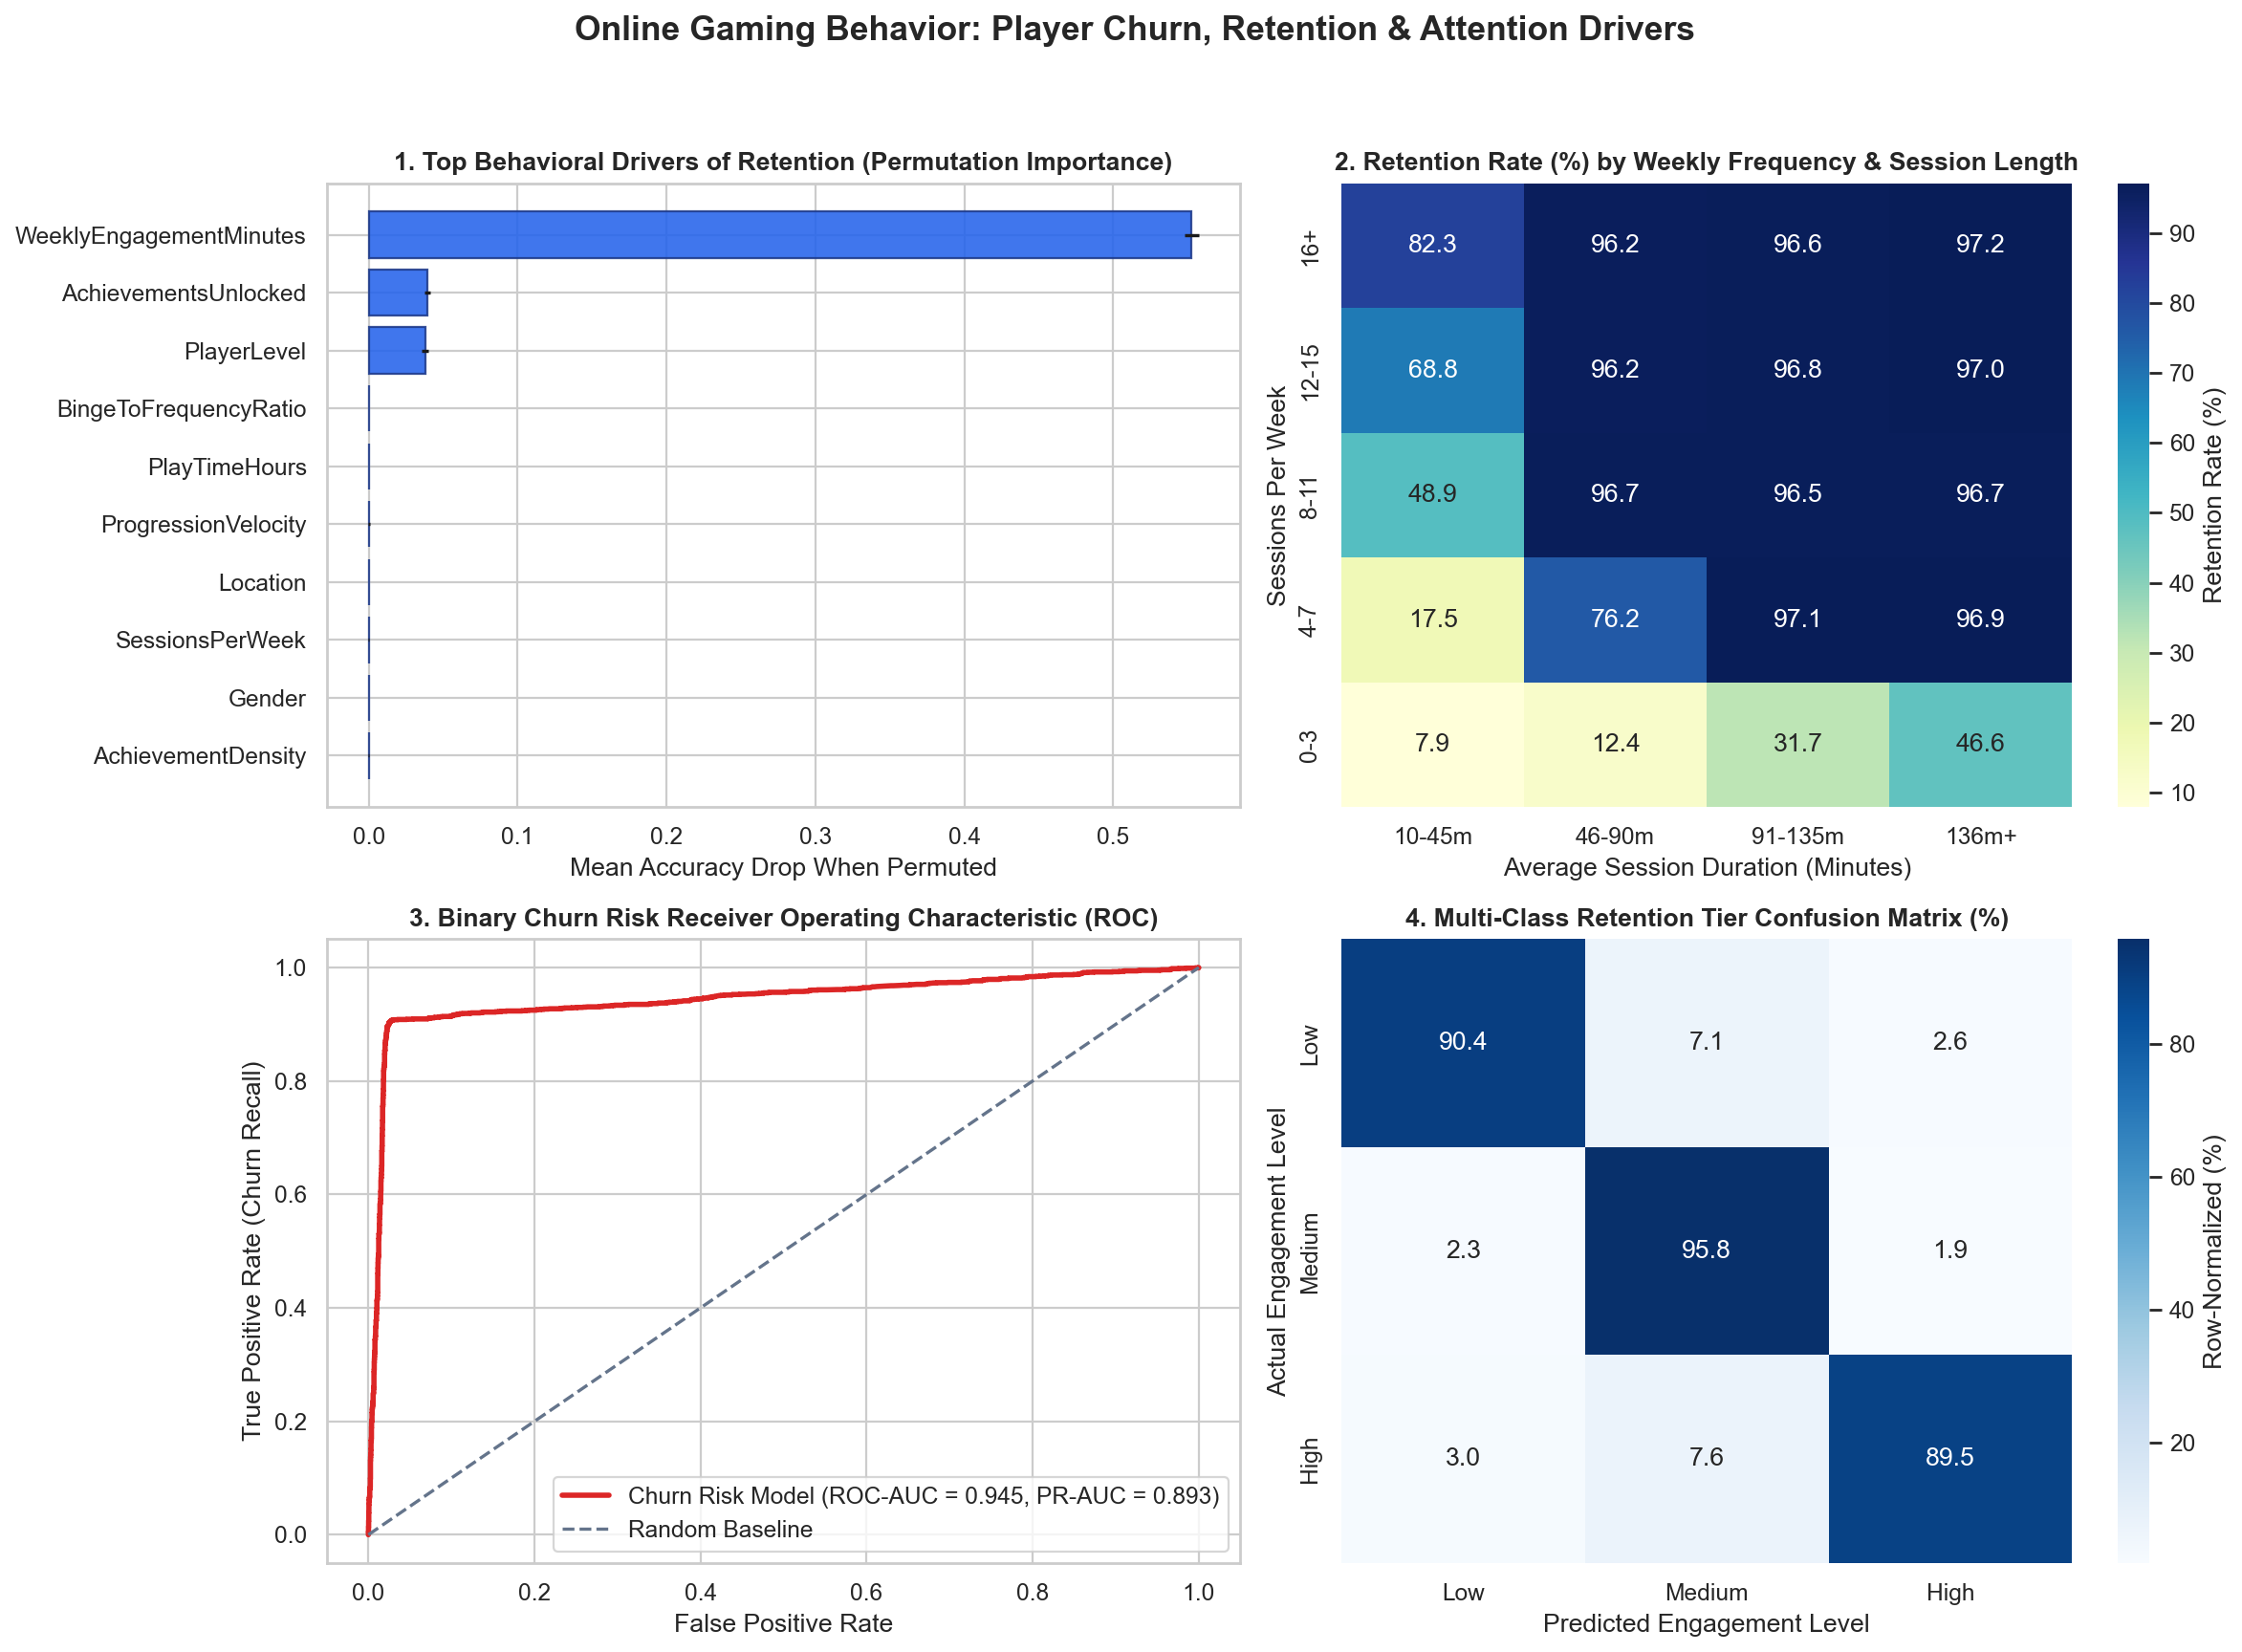

,PlayerID,Age,PlayTimeHours,InGamePurchases,SessionsPerWeek,AvgSessionDurationMinutes,PlayerLevel,AchievementsUnlocked,WeeklyEngagementMinutes,AchievementDensity,...,BingeToFrequencyRatio,MonetizedSessionScore,Gender,Location,GameGenre,GameDifficulty,ActualTier,PredictedTier,ChurnProbability,RecommendedIntervention
21667,30667,30,2.700996,0,0,177,7,9,0,1.125000,...,177.0,0,Male,Asia,RPG,Easy,Low,Low,0.9765,Habit Loop: Trigger daily login/streak reward ...
7471,16471,32,12.034373,1,0,178,27,8,0,0.285714,...,178.0,0,Female,Asia,Action,Easy,Low,Low,0.9744,Habit Loop: Trigger daily login/streak reward ...
20173,29173,31,12.513254,0,1,179,28,16,179,0.551724,...,89.5,0,Male,Europe,Action,Hard,Low,Low,0.9742,Habit Loop: Trigger daily login/streak reward ...
9417,18417,17,0.453050,0,0,150,15,8,0,0.500000,...,150.0,0,Male,USA,Strategy,Medium,Low,Low,0.9726,Habit Loop: Trigger daily login/streak reward ...
16729,25729,34,6.153154,0,1,179,1,36,179,18.000000,...,89.5,0,Male,USA,RPG,Medium,Low,Low,0.9702,Habit Loop: Trigger daily login/streak reward ...
10688,19688,23,16.749208,0,0,152,27,24,0,0.857143,...,152.0,0,Male,Europe,Action,Easy,Low,Low,0.9693,Habit Loop: Trigger daily login/streak reward ...
35041,44041,35,19.831938,0,0,159,16,17,0,1.000000,...,159.0,0,Female,Europe,Action,Hard,Low,Low,0.9687,Habit Loop: Trigger daily login/streak reward ...
9925,18925,29,10.726771,0,0,118,17,12,0,0.666667,...,118.0,0,Female,USA,Strategy,Easy,Low,Low,0.9684,Habit Loop: Trigger daily login/streak reward ...
15758,24758,20,11.512130,0,0,146,19,5,0,0.250000,...,146.0,0,Female,Europe,Simulation,Medium,Low,Low,0.9681,Habit Loop: Trigger daily login/streak reward ...
15817,24817,44,22.224053,1,0,136,5,23,0,3.833333,...,136.0,0,Male,Europe,RPG,Easy,Medium,Low,0.9678,Habit Loop: Trigger daily login/streak reward ...


In [56]:
def save_diagnostic_dashboard(
    df: pd.DataFrame,
    results: dict,
    output_path: Path,
) -> None:
    """Renders a 4-panel visual analytics dashboard for player retention and churn."""
    sns.set_theme(style="whitegrid", palette="deep")
    fig, axes = plt.subplots(2, 2, figsize=(15, 11), dpi=160)
    fig.suptitle(
        "Online Gaming Behavior: Player Churn, Retention & Attention Drivers",
        fontsize=16,
        fontweight="bold",
        y=0.98,
    )

    # Panel 1: Permutation Feature Importance (What drives retention?)
    ax1 = axes[0, 0]
    top_imp = results["importance_df"].head(10).iloc[::-1]
    ax1.barh(
        top_imp["Feature"],
        top_imp["ImportanceMean"],
        xerr=top_imp["ImportanceStd"],
        color="#2563eb",
        alpha=0.88,
        edgecolor="#1e3a8a",
    )
    ax1.set_title("1. Top Behavioral Drivers of Retention (Permutation Importance)", fontweight="bold")
    ax1.set_xlabel("Mean Accuracy Drop When Permuted")

    # Panel 2: Attention Heatmap (SessionsPerWeek vs. AvgSessionDurationMinutes)
    ax2 = axes[0, 1]
    df_plot = df.copy()
    df_plot["SessionFreqBin"] = pd.cut(
        df_plot["SessionsPerWeek"],
        bins=[-1, 3, 7, 11, 15, 25],
        labels=["0-3", "4-7", "8-11", "12-15", "16+"],
    )
    df_plot["DurationBin"] = pd.cut(
        df_plot["AvgSessionDurationMinutes"],
        bins=[0, 45, 90, 135, 200],
        labels=["10-45m", "46-90m", "91-135m", "136m+"],
    )
    pivot_ret = (
        df_plot.pivot_table(
            index="SessionFreqBin",
            columns="DurationBin",
            values="ChurnRisk",
            aggfunc=lambda s: 1.0 - s.mean(),
            observed=False,
        )
        * 100.0
    )
    sns.heatmap(
        pivot_ret.iloc[::-1],
        annot=True,
        fmt=".1f",
        cmap="YlGnBu",
        cbar_kws={"label": "Retention Rate (%)"},
        ax=ax2,
    )
    ax2.set_title("2. Retention Rate (%) by Weekly Frequency & Session Length", fontweight="bold")
    ax2.set_xlabel("Average Session Duration (Minutes)")
    ax2.set_ylabel("Sessions Per Week")

    # Panel 3: Binary Churn ROC Curve
    ax3 = axes[1, 0]
    ax3.plot(
        results["fpr"],
        results["tpr"],
        color="#dc2626",
        lw=2.5,
        label=f"Churn Risk Model (ROC-AUC = {results['roc_auc']:.3f}, PR-AUC = {results['pr_auc']:.3f})",
    )
    ax3.plot([0, 1], [0, 1], linestyle="--", color="#64748b", label="Random Baseline")
    ax3.set_title("3. Binary Churn Risk Receiver Operating Characteristic (ROC)", fontweight="bold")
    ax3.set_xlabel("False Positive Rate")
    ax3.set_ylabel("True Positive Rate (Churn Recall)")
    ax3.legend(loc="lower right")

    # Panel 4: Multi-Class Confusion Matrix (Low, Medium, High Engagement)
    ax4 = axes[1, 1]
    sns.heatmap(
        results["cm_norm"],
        annot=True,
        fmt=".1f",
        cmap="Blues",
        xticklabels=ENGAGEMENT_ORDER,
        yticklabels=ENGAGEMENT_ORDER,
        cbar_kws={"label": "Row-Normalized (%)"},
        ax=ax4,
    )
    ax4.set_title("4. Multi-Class Retention Tier Confusion Matrix (%)", fontweight="bold")
    ax4.set_xlabel("Predicted Engagement Level")
    ax4.set_ylabel("Actual Engagement Level")

    plt.tight_layout(rect=[0, 0, 1, 0.95])
    output_path.parent.mkdir(parents=True, exist_ok=True)
    plt.savefig(output_path, bbox_inches="tight")
    plt.show()

save_diagnostic_dashboard(df, results, Path("retention_analytics_dashboard.png"))

results["watchlist"].head(10)

CLI Entrypoint

In [57]:
def main() -> None:
    parser = argparse.ArgumentParser(
        description="Train player churn/retention models and analyze attention drivers."
    )
    parser.add_argument(
        "--data",
        type=str,
        default="online_gaming_behavior_dataset.csv",
        help="Path to online_gaming_behavior_dataset.csv",
    )
    parser.add_argument(
        "--demo",
        action="store_true",
        help="Generate and run on a schema-accurate synthetic dataset if the CSV is not present.",
    )
    parser.add_argument(
        "--out-dir",
        type=str,
        default=".",
        help="Directory to save the dashboard PNG and at-risk watchlist CSV.",
    )
    args = parser.parse_args()

    data_path = Path(args.data)
    out_dir = Path(args.out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)

    if data_path.exists() and not args.demo:
        print(f"[INFO] Loading Kaggle dataset from: {data_path.resolve()}")
        raw_df = pd.read_csv(data_path)
    else:
        print(
            f"[INFO] '{data_path}' not found locally or --demo specified. "
            "Generating schema-accurate synthetic dataset (n=5,000) for validation..."
        )
        raw_df = generate_schema_accurate_demo_data(n_samples=5000, seed=42)

    missing_cols = [c for c in REQUIRED_COLUMNS if c not in raw_df.columns]
    if missing_cols:
        raise ValueError(f"Dataset is missing required Kaggle columns: {missing_cols}")

    df = engineer_behavioral_features(raw_df)
    results = train_and_evaluate_models(df)
    cluster_summary, _ = analyze_player_archetypes_and_gravitation(df)

    dashboard_path = out_dir / "retention_analytics_dashboard.png"
    watchlist_path = out_dir / "at_risk_players_watchlist.csv"
    save_diagnostic_dashboard(df, results, dashboard_path)
    results["watchlist"].head(250).to_csv(watchlist_path, index=False)

    print("\n" + "=" * 78)
    print("1. MODEL PERFORMANCE SUMMARY (CHURN & RETENTION TIERS)")
    print("=" * 78)
    print(f"Binary Churn Risk (Low vs. Med/High) Test ROC-AUC : {results['roc_auc']:.4f}")
    print(f"Binary Churn Risk (Low vs. Med/High) Test PR-AUC  : {results['pr_auc']:.4f}")
    print(
        f"Multi-Class Retention Tier 5-Fold CV Accuracy     : "
        f"{results['gb_cv_mean']:.4f} (+/- {results['gb_cv_std']:.4f})"
    )
    print("\nTest Set Classification Report (EngagementLevel: Low, Medium, High):")
    print(results["report_str"])

    print("\n" + "=" * 78)
    print("2. TOP ATTENTION & RETENTION DRIVERS (PERMUTATION IMPORTANCE)")
    print("=" * 78)
    print(results["importance_df"].head(10).to_string(index=False))

    print("\n" + "=" * 78)
    print("3. DISCOVERED PLAYER ARCHETYPES (K-MEANS++ BEHAVIORAL CLUSTERING)")
    print("=" * 78)
    print(cluster_summary.to_string(index=False))

    print("\n" + "=" * 78)
    print("4. SAMPLE AT-RISK PLAYERS WATCHLIST & RECOMMENDED INTERVENTIONS")
    print("=" * 78)
    cols_preview = [
        "PlayerID",
        "GameGenre",
        "SessionsPerWeek",
        "AvgSessionDurationMinutes",
        "AchievementsUnlocked",
        "ChurnProbability",
        "RecommendedIntervention",
    ]
    print(results["watchlist"][cols_preview].head(8).to_string(index=False))
    print(f"\n[SAVED] Dashboard plot : {dashboard_path.resolve()}")
    print(f"[SAVED] Watchlist CSV  : {watchlist_path.resolve()}")

if __name__ == "__main__":
    main()

usage: ipykernel_launcher.py [-h] [--data DATA] [--demo] [--out-dir OUT_DIR]
ipykernel_launcher.py: error: unrecognized arguments: --f=/Users/otispratt/Library/Jupyter/runtime/kernel-v3c2933f8fcb6fcae087bfa59871885aa7d8496bfc.json


SystemExit: 2

/Users/otispratt/Library/Python/3.13/lib/python/site-packages/IPython/core/interactiveshell.py:3831: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)
